# Fitting a diurnal cycle

Fit the diurnal cycle of air temperature.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

import xclimatology  # noqa: F401 (registers the .climatology accessor)

## Load the data

We use 6-hourly NCEP reanalysis air temperature near the surface over North America for
2013–2014, from the xarray tutorial datasets.

In [3]:
air = xr.tutorial.load_dataset("air_temperature")["air"]
air

<xarray.DataArray 'air' (time: 2920, lat: 25, lon: 53)> Size: 31MB
array([[[241.2 , 242.5 , 243.5 , ..., 232.8 , 235.5 , 238.6 ],
        [243.8 , 244.5 , 244.7 , ..., 232.8 , 235.3 , 239.3 ],
        [250.  , 249.8 , 248.89, ..., 233.2 , 236.39, 241.7 ],
        ...,
        [296.6 , 296.2 , 296.4 , ..., 295.4 , 295.1 , 294.7 ],
        [295.9 , 296.2 , 296.79, ..., 295.9 , 295.9 , 295.2 ],
        [296.29, 296.79, 297.1 , ..., 296.9 , 296.79, 296.6 ]],

       [[242.1 , 242.7 , 243.1 , ..., 232.  , 233.6 , 235.8 ],
        [243.6 , 244.1 , 244.2 , ..., 231.  , 232.5 , 235.7 ],
        [253.2 , 252.89, 252.1 , ..., 230.8 , 233.39, 238.5 ],
        ...,
        [296.4 , 295.9 , 296.2 , ..., 295.4 , 295.1 , 294.79],
        [296.2 , 296.7 , 296.79, ..., 295.6 , 295.5 , 295.1 ],
        [296.29, 297.2 , 297.4 , ..., 296.4 , 296.4 , 296.6 ]],

       [[242.3 , 242.2 , 242.3 , ..., 234.3 , 236.1 , 238.7 ],
        [244.6 , 244.39, 244.  , ..., 230.3 , 232.  , 235.7 ],
        [256.2 , 255.5 , 254.2 , ..., 231.2 , 233.2 , 238.2 ],
        ...,
...
        [294.79, 295.29, 297.49, ..., 295.49, 295.39, 294.69],
        [296.79, 297.89, 298.29, ..., 295.49, 295.49, 294.79],
        [298.19, 299.19, 298.79, ..., 296.09, 295.79, 295.79]],

       [[245.79, 244.79, 243.49, ..., 243.29, 243.99, 244.79],
        [249.89, 249.29, 248.49, ..., 241.29, 242.49, 244.29],
        [262.39, 261.79, 261.29, ..., 240.49, 243.09, 246.89],
        ...,
        [293.69, 293.89, 295.39, ..., 295.09, 294.69, 294.29],
        [296.29, 297.19, 297.59, ..., 295.29, 295.09, 294.39],
        [297.79, 298.39, 298.49, ..., 295.69, 295.49, 295.19]],

       [[245.09, 244.29, 243.29, ..., 241.69, 241.49, 241.79],
        [249.89, 249.29, 248.39, ..., 239.59, 240.29, 241.69],
        [262.99, 262.19, 261.39, ..., 239.89, 242.59, 246.29],
        ...,
        [293.79, 293.69, 295.09, ..., 295.29, 295.09, 294.69],
        [296.09, 296.89, 297.19, ..., 295.69, 295.69, 295.19],
        [297.69, 298.09, 298.09, ..., 296.49, 296.19, 295.69]]],
      shape=(2920, 25, 53))
Coordinates:
  * time     (time) datetime64[ns] 23kB 2013-01-01 ... 2014-12-31T18:00:00
  * lat      (lat) float32 100B 75.0 72.5 70.0 67.5 65.0 ... 22.5 20.0 17.5 15.0
  * lon      (lon) float32 212B 200.0 202.5 205.0 207.5 ... 325.0 327.5 330.0
Attributes:
    long_name:     4xDaily Air temperature at sigma level 995
    units:         degK
    precision:     2
    GRIB_id:       11
    GRIB_name:     TMP
    var_desc:      Air temperature
    dataset:       NMC Reanalysis
    level_desc:    Surface
    statistic:     Individual Obs
    parent_stat:   Other
    actual_range:  [185.16 322.1 ]

## Remove the seasonal cycle

Subtract the seasonal climatology (linear polynomial and annual and semiannual harmonics)
to obtain the seasonal anomaly.

In [4]:
seasonal = dict(n_harmonics=2, period=1, period_units="year", detrend_degree=1)

seasonal_anomaly = air - air.climatology(**seasonal)

## Fit the diurnal cycle

`seasonal_anomaly.climatology(**diurnal)` fits, at each grid point, the climatology

\begin{align*}
\bar{y}(t) &= c_0 + a \cos(\omega t) + b \sin(\omega t), \\
\omega &= \frac{2\pi}{T},
\end{align*}

where $y$ is now the seasonal anomaly, $t$ is in days, $T = 1$ day, and $c_0$ is a
constant. `n_harmonics=1` keeps only the diurnal harmonic, `period` and `period_units`
set $T$, and `detrend_degree=0` keeps only $c_0$, since the seasonal climatology already
removed the trend.
Phases are measured from midnight of the time coordinate, 00 UTC for these data.

In [5]:
diurnal = dict(n_harmonics=1, period=1, period_units="day", detrend_degree=0)

diurnal_clim = seasonal_anomaly.climatology(**diurnal)
diurnal_clim

<xarray.DataArray 'air' (time: 2920, lat: 25, lon: 53)> Size: 31MB
array([[[ 0.65653648,  0.68828446,  0.74551597, ...,  0.09079638,
          0.02795117, -0.03071551],
        [ 0.41735172,  0.42301981,  0.44169092, ..., -0.06934595,
         -0.20251071, -0.3123269 ],
        [ 0.99490174,  1.11392881,  1.16172349, ..., -0.16330254,
         -0.2450352 , -0.26738218],
        ...,
        [ 0.54714894,  0.6572247 ,  0.64211056, ..., -0.06505869,
          0.11406382,  0.03260835],
        [ 0.33355008,  0.39471815,  0.46468765, ...,  0.02829033,
          0.09507335,  0.02914857],
        [ 0.22639694,  0.28342219,  0.30003477, ...,  0.02366225,
          0.11709766,  0.05363043]],

       [[ 0.34107757,  0.31963377,  0.31459131, ..., -1.59945704,
         -1.47358308, -1.31535935],
        [ 0.22330378,  0.15283488,  0.12298544, ..., -2.09289389,
         -1.96329838, -1.74086114],
        [ 0.70831955,  0.71364114,  0.68516869, ..., -2.38191898,
         -2.14122013, -1.76758081],
...
        [-0.54714894, -0.6572247 , -0.64211056, ...,  0.06505869,
         -0.11406382, -0.03260835],
        [-0.33355008, -0.39471815, -0.46468765, ..., -0.02829033,
         -0.09507335, -0.02914857],
        [-0.22639694, -0.28342219, -0.30003477, ..., -0.02366225,
         -0.11709766, -0.05363043]],

       [[-0.34107757, -0.31963377, -0.31459131, ...,  1.59945704,
          1.47358308,  1.31535935],
        [-0.22330378, -0.15283488, -0.12298544, ...,  2.09289389,
          1.96329838,  1.74086114],
        [-0.70831955, -0.71364114, -0.68516869, ...,  2.38191898,
          2.14122013,  1.76758081],
        ...,
        [-0.33520373, -0.35357402, -0.38000097, ...,  0.35045595,
          0.17468275,  0.23387795],
        [-0.27810487, -0.27569076, -0.24792738, ...,  0.34455899,
          0.19320063,  0.29882403],
        [-0.18267092, -0.26560027, -0.22258271, ...,  0.37640624,
          0.2253681 ,  0.21284903]]], shape=(2920, 25, 53))
Coordinates:
  * time     (time) datetime64[ns] 23kB 2013-01-01 ... 2014-12-31T18:00:00
  * lat      (lat) float32 100B 75.0 72.5 70.0 67.5 65.0 ... 22.5 20.0 17.5 15.0
  * lon      (lon) float32 212B 200.0 202.5 205.0 207.5 ... 325.0 327.5 330.0
Attributes:
    long_name:     4xDaily Air temperature at sigma level 995
    units:         degK
    precision:     2
    GRIB_id:       11
    GRIB_name:     TMP
    var_desc:      Air temperature
    dataset:       NMC Reanalysis
    level_desc:    Surface
    statistic:     Individual Obs
    parent_stat:   Other
    actual_range:  [185.16 322.1 ]

At a single grid point, over two weeks of July:

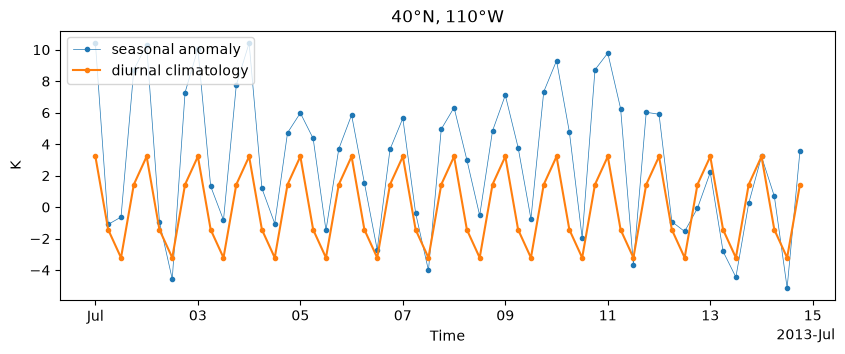

In [6]:
point = dict(lat=40, lon=250)
july = slice("2013-07-01", "2013-07-14")

fig, ax = plt.subplots(figsize=(10, 3.5))
seasonal_anomaly.sel(**point).sel(time=july).plot(ax=ax, marker=".", lw=0.5, label="seasonal anomaly")
diurnal_clim.sel(**point).sel(time=july).plot(ax=ax, marker=".", lw=1.5, label="diurnal climatology")
ax.set(title="40°N, 110°W", ylabel="K")
ax.legend(loc="upper left");

The fit uses one amplitude for both years, so it underestimates the larger diurnal
range of summer.

## Amplitude and phase

`seasonal_anomaly.climatology.coefficients(**diurnal)` returns the fitted coefficients
with the amplitude $A$ and phase $\phi$ of the diurnal harmonic,

\begin{align*}
a \cos(\omega t) + b \sin(\omega t) &= A \cos(\omega t - \phi), \\
A &= \sqrt{a^2 + b^2}, \\
\phi &= \mathrm{atan2}(b, a).
\end{align*}

The harmonic peaks where $\omega t - \phi = 2\pi n$. `atan2` returns $\phi$ in
$[-\pi, \pi]$, so the first peak after 00 UTC is at

$$
t_{\mathrm{peak}} = \frac{\phi \bmod 2\pi}{\omega}
$$

days. $t_{\mathrm{peak}}$ is the peak of the fitted sinusoid, which repeats every day, and can differ
from the time of the largest observed value. In local solar time, with $\lambda$ the
longitude east, the peak falls at approximately

$$
t_{\mathrm{peak}}^{\mathrm{solar}} = \left(24\,t_{\mathrm{peak}} + \frac{\lambda}{15^\circ}\right) \bmod 24
$$

hours.

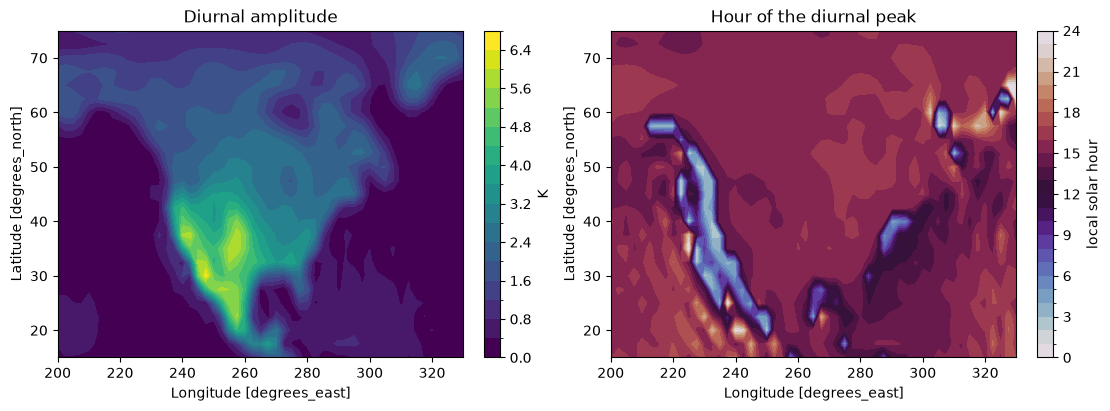

In [7]:
coefs = seasonal_anomaly.climatology.coefficients(**diurnal).sel(harmonic=1)
hour_utc = (coefs["phase"] % (2 * np.pi)) / (2 * np.pi) * 24
hour = (hour_utc + air["lon"] / 15) % 24

fig, axes = plt.subplots(ncols=2, figsize=(11, 4), constrained_layout=True)
coefs["amplitude"].plot.contourf(ax=axes[0], levels=21, cbar_kwargs={"label": "K"})
axes[0].set_title("Diurnal amplitude")
hour.plot.contourf(
    ax=axes[1], cmap="twilight", levels=np.arange(0, 25),
    cbar_kwargs={"label": "local solar hour", "ticks": np.arange(0, 25, 3)},
)
axes[1].set_title("Hour of the diurnal peak");

Over land the diurnal harmonic peaks in mid-afternoon, and its amplitude is largest over
the deserts of the southwestern United States and northwestern Mexico.